Predict future averge price of Cereals and Tubers monthly in Yangon by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2011-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2012-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DCTM_Y = data.copy()
mask = (DCTM_Y['category']=='cereals and tubers') & (DCTM_Y['region']=='Yangon')
DCTM_Y = DCTM_Y.loc[mask]
DCTM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4079,1/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,845.00,0.4747
4080,1/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,KG,actual,Wholesale,MMK,307.76,0.1729
4334,2/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,865.01,0.4860
4335,2/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,KG,actual,Wholesale,MMK,328.66,0.1846
4610,3/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,888.24,0.4990


In [13]:
DCTM_Y = DCTM_Y[['date', 'price']]
DCTM_Y['date'] = pd.to_datetime(DCTM_Y['date'])
mask = (DCTM_Y['date']>=obv_st_date) & (DCTM_Y['date']<=obv_end_date)
DCTM_Y = DCTM_Y.loc[mask]
DCTM_Y = DCTM_Y.set_index('date')
DCTM_Y.head()

,price
date,
2011-01-15,845.00
2011-01-15,307.76
2011-02-15,865.01
2011-02-15,328.66
2011-03-15,888.24


In [14]:
DCTM_Y = DCTM_Y.resample('MS').mean()
DCTM_Y.head()

,price
date,
2011-01-01,576.380
2011-02-01,596.835
2011-03-01,618.900
2011-04-01,615.000
2011-05-01,622.470


In [15]:
DCTM_Y.shape

(133, 1)

In [16]:
price = DCTM_Y['price']
date = DCTM_Y.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DCTM_Y_nor = scaler.fit_transform(DCTM_Y)
DCTM_Y_nor = pd.DataFrame(DCTM_Y_nor)
DCTM_Y_nor.head()

,0
0,0.051972
1,0.071889
2,0.093374
3,0.089577
4,0.096851


In [19]:
DCTM_Y_nor['date']=date
DCTM_Y_nor = DCTM_Y_nor.set_index('date')
DCTM_Y_nor.columns=['price']
DCTM_Y_nor.head()

,price
date,
2011-01-01,0.051972
2011-02-01,0.071889
2011-03-01,0.093374
2011-04-01,0.089577
2011-05-01,0.096851


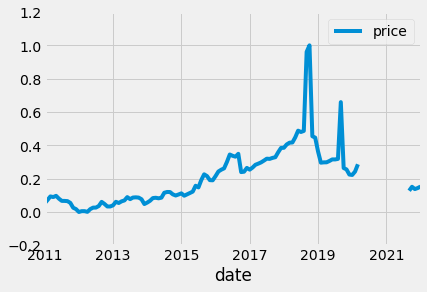

In [20]:
DCTM_Y_nor.plot(grid=True)
plt.show()

#####  Filling data with linear interpolation

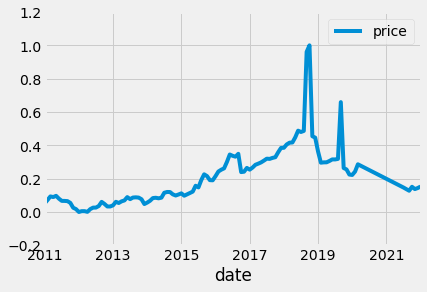

In [21]:
DCTM_Y_nor = DCTM_Y_nor.interpolate(method='linear')
DCTM_Y_nor.plot(grid=True)
plt.show()

It has upward trend. So it has difference = 1

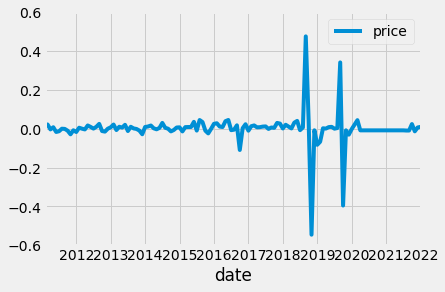

In [22]:
DCTM_Y_nor_diff1 = DCTM_Y_nor.diff(1).dropna()
DCTM_Y_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [23]:
RW_DCTM_Y= adfuller(DCTM_Y_nor_diff1)
RW_DCTM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

0.018923148599768628

##### Plotting ACF and PACF

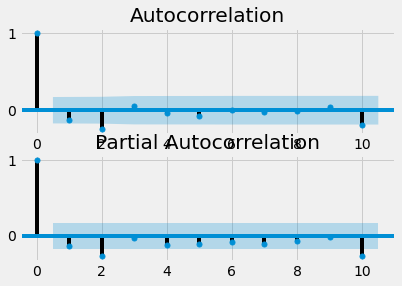

In [24]:
fig, axes=plt.subplots(2,1)
plot_acf(DCTM_Y_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DCTM_Y_nor_diff1, lags=10, ax=axes[1])
plt.show()

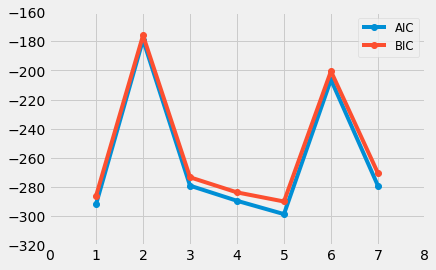

In [25]:
AIC, BIC = AIC_BIC_withOrderRange(DCTM_Y_nor_diff1, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [26]:
AIC, BIC

(array([-289.17454558, -291.86639534, -178.97412385, -279.10149181,
        -289.47454683, -298.6047235 , -206.36219737, -279.14284049]),
 array([-286.29174365, -286.10079149, -176.09892653, -273.35109716,
        -283.70894298, -289.95631773, -200.61180273, -270.51724852]))

We will run again 1:(0,0,1), 5:(1,0,1)

In [27]:
mod_orders = [
    (0,0,1),
    (1,0,1),
]

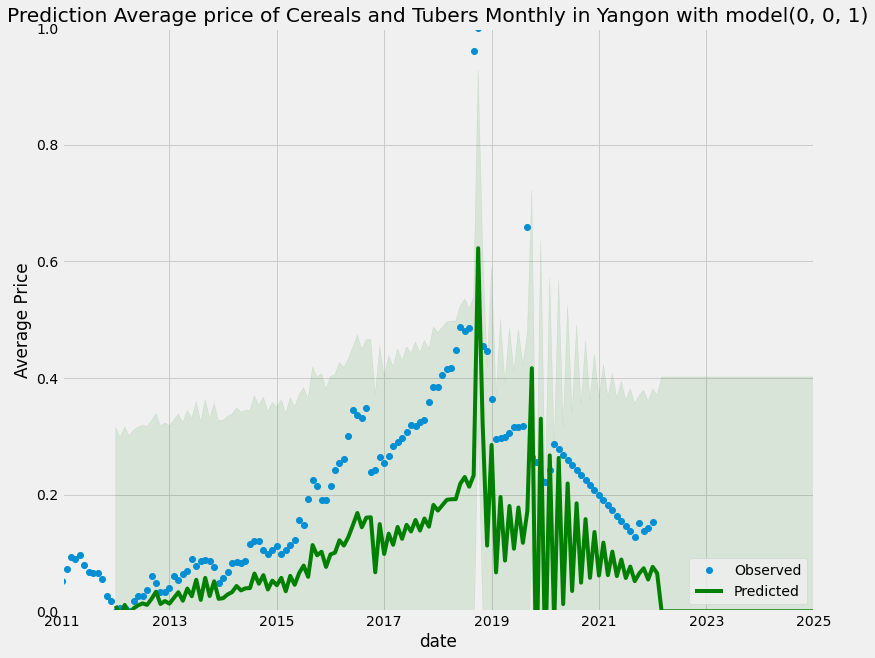

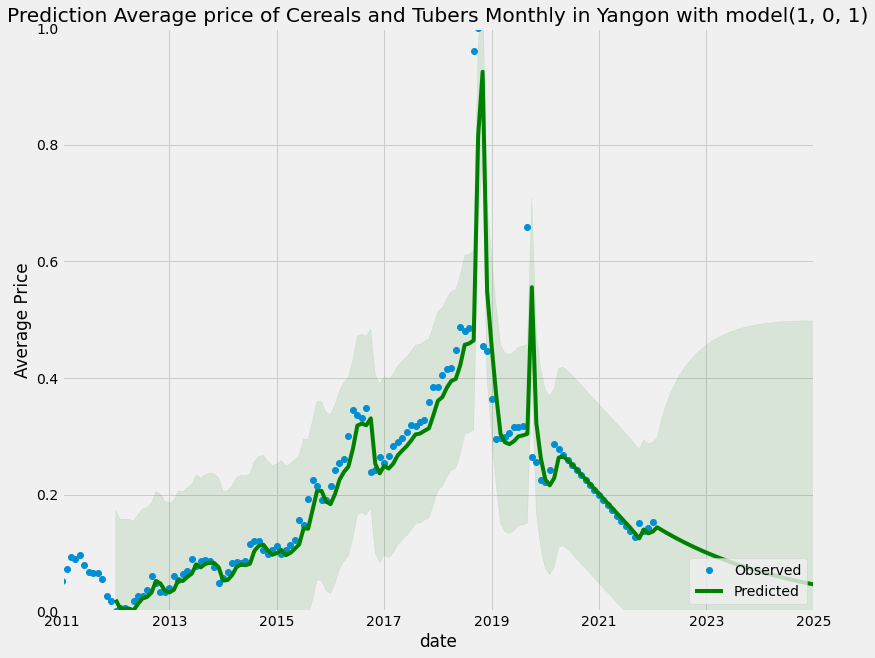

In [28]:
DCTM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DCTM_Y_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Cereals and Tubers Monthly in Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DCTM_Y_models.append(model)

Now we choose (1,0,0)

In [29]:
DCTM_Y_model = DCTM_Y_models[1]

In [30]:
DCTM_Y_pred_normalized = DCTM_Y_model.predict(pred_st_date, pred_end_date)
DCTM_Y_pred_normalized 

2012-01-01    0.019878
2012-02-01    0.004607
2012-03-01    0.004655
2012-04-01    0.004624
2012-05-01    0.001688
                ...   
2024-09-01    0.052451
2024-10-01    0.050769
2024-11-01    0.049141
2024-12-01    0.047565
2025-01-01    0.046040
Freq: MS, Length: 157, dtype: float64

In [31]:
mask = (DCTM_Y_nor.index>=pred_st_date) & (DCTM_Y_nor.index<=pred_end_date)
DCTM_Y_pred = DCTM_Y_nor.loc[mask]
DCTM_Y_pred

,price
date,
2012-01-01,0.000000
2012-02-01,0.004873
2012-03-01,0.004815
2012-04-01,0.000837
2012-05-01,0.017176
...,...
2021-09-01,0.127530
2021-10-01,0.151116
2021-11-01,0.137447


We need to un-normalized the predicted value to get actual price

In [32]:
pred_date = DCTM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2012-01-01', '2012-02-01', '2012-03-01', '2012-04-01',
               '2012-05-01', '2012-06-01', '2012-07-01', '2012-08-01',
               '2012-09-01', '2012-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=156, freq='MS')

In [33]:
DCTM_Y_pred_normalized_df = pd.DataFrame(DCTM_Y_pred_normalized)
DCTM_Y_pred_normalized_df = DCTM_Y_pred_normalized_df[:-1] # the last index doesn't need
DCTM_Y_pred_normalized_df

,0
2012-01-01,0.019878
2012-02-01,0.004607
2012-03-01,0.004655
2012-04-01,0.004624
2012-05-01,0.001688
...,...
2024-08-01,0.054189
2024-09-01,0.052451
2024-10-01,0.050769
2024-11-01,0.049141


##### Un-normalization data

In [34]:
DCTM_Y_pred_act = scaler.inverse_transform(DCTM_Y_pred_normalized_df)
DCTM_Y_pred_act_df = pd.DataFrame(DCTM_Y_pred_act)
DCTM_Y_pred_act_df['date'] = pred_date
DCTM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DCTM_Y_pred_act_df.set_index('date',  inplace=True)
DCTM_Y_pred_act_df

,Predicted Price
date,
2012-01-01,543.419239
2012-02-01,527.736510
2012-03-01,527.786113
2012-04-01,527.753440
2012-05-01,524.738665
...,...
2024-08-01,578.656614
2024-09-01,576.871994
2024-10-01,575.144603


In [35]:
mask = (DCTM_Y.index>=pred_st_date) & (DCTM_Y.index<=pred_end_date)
DCTM_Y_Act = DCTM_Y.loc[mask]
DCTM_Y_Act

,price
date,
2012-01-01,523.0050
2012-02-01,528.0100
2012-03-01,527.9500
2012-04-01,523.8650
2012-05-01,540.6450
...,...
2021-09-01,653.9775
2021-10-01,678.2000
2021-11-01,664.1620


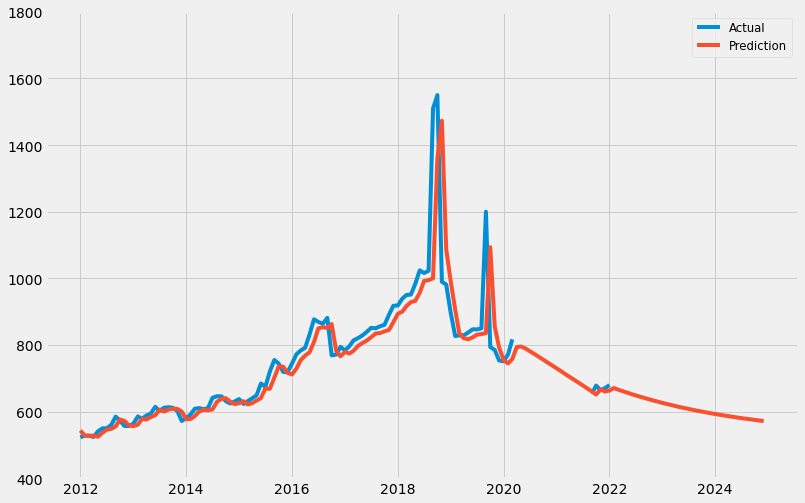

In [36]:
plt.figure(figsize=(12,8))
plt.plot(DCTM_Y_Act, label="Actual")
plt.plot(DCTM_Y_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [37]:
temp_df = DCTM_Y_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2011-01-01,0.051972
1,2011-02-01,0.071889
2,2011-03-01,0.093374
3,2011-04-01,0.089577
4,2011-05-01,0.096851
...,...,...
128,2021-09-01,0.127530
129,2021-10-01,0.151116
130,2021-11-01,0.137447
131,2021-12-01,0.143548


In [38]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2011-01-01  0.051972  1293840000000000000
 1   2011-02-01  0.071889  1296518400000000000
 2   2011-03-01  0.093374  1298937600000000000
 5   2011-06-01  0.079801  1306886400000000000
 6   2011-07-01  0.066568  1309478400000000000
 ..         ...       ...                  ...
 127 2021-08-01  0.137156  1627776000000000000
 128 2021-09-01  0.127530  1630454400000000000
 130 2021-11-01  0.137447  1635724800000000000
 131 2021-12-01  0.143548  1638316800000000000
 132 2022-01-01  0.152674  1640995200000000000
 
 [106 rows x 3 columns],
           date     price                 time
 3   2011-04-01  0.089577  1301616000000000000
 4   2011-05-01  0.096851  1304208000000000000
 9   2011-10-01  0.054543  1317427200000000000
 10  2011-11-01  0.025438  1320105600000000000
 14  2012-03-01  0.004815  1330560000000000000
 21  2012-10-01  0.048228  1349049600000000000
 25  2013-02-01  0.061062  1359676800000000000
 33  2013-10-01  0.086261  138058

In [39]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1293840000000000000],
        [1296518400000000000],
        [1298937600000000000],
        [1306886400000000000],
        [1309478400000000000],
        [1312156800000000000],
        [1314835200000000000],
        [1322697600000000000],
        [1325376000000000000],
        [1328054400000000000]], dtype=int64),
 array([0.05197202, 0.07188935, 0.09337436, 0.07980078, 0.066568  ,
        0.06636352, 0.06505874, 0.01711303, 0.        , 0.00487344]))

In [40]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1301616000000000000],
        [1304208000000000000],
        [1317427200000000000],
        [1320105600000000000],
        [1330560000000000000],
        [1349049600000000000],
        [1359676800000000000],
        [1380585600000000000],
        [1385856000000000000],
        [1412121600000000000]], dtype=int64),
 array([0.08957687, 0.09685052, 0.05454262, 0.02543829, 0.00481502,
        0.04822808, 0.06106164, 0.08626137, 0.04769254, 0.10572593]))

In [41]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [42]:
DCTM_Y_linreg = LinearRegression().fit(X_train, y_train)

In [43]:
print('linear model coeff or slope (w): {}'.format(DCTM_Y_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DCTM_Y_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DCTM_Y_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DCTM_Y_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [8.72162502e-19]
linear model intercept (b): -1.075
R-squared score (training): 0.275
R-squared score (test): 0.500


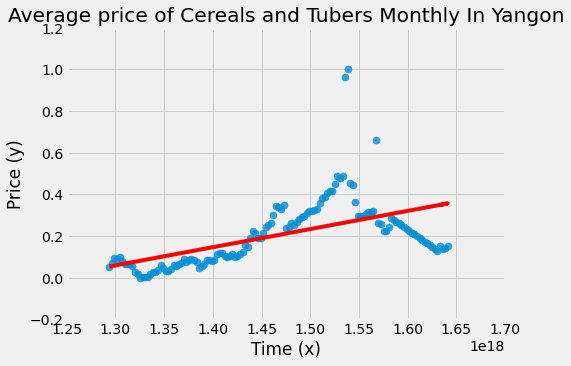

In [44]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DCTM_Y_linreg.coef_ * X + DCTM_Y_linreg.intercept_, 'r-')
plt.title('Average price of Cereals and Tubers Monthly In Yangon')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [45]:
DCTM_Y_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DCTM_Y_linear_predict['time'] = DCTM_Y_linear_predict['date'].apply(lambda x: x.value)
DCTM_Y_linear_predict

,date,time
0,2012-01-01,1325376000000000000
1,2012-02-01,1328054400000000000
2,2012-03-01,1330560000000000000
3,2012-04-01,1333238400000000000
4,2012-05-01,1335830400000000000
...,...,...
152,2024-09-01,1725148800000000000
153,2024-10-01,1727740800000000000
154,2024-11-01,1730419200000000000
155,2024-12-01,1733011200000000000


In [46]:
time_predict = np.array(DCTM_Y_linear_predict['time']).reshape((-1, 1))
DCTM_Y_linear_predict['price'] = DCTM_Y_linreg.predict(time_predict)
DCTM_Y_linear_predict

,date,time,price
0,2012-01-01,1325376000000000000,0.081010
1,2012-02-01,1328054400000000000,0.083346
2,2012-03-01,1330560000000000000,0.085531
3,2012-04-01,1333238400000000000,0.087867
4,2012-05-01,1335830400000000000,0.090128
...,...,...,...
152,2024-09-01,1725148800000000000,0.429677
153,2024-10-01,1727740800000000000,0.431937
154,2024-11-01,1730419200000000000,0.434273
155,2024-12-01,1733011200000000000,0.436534


In [47]:
DCTM_Y_linear_normalized_predict = DCTM_Y_linear_predict.copy()
DCTM_Y_linear_normalized_predict = DCTM_Y_linear_normalized_predict[['date', 'price']]
DCTM_Y_linear_normalized_predict.set_index('date', inplace=True)
DCTM_Y_linear_normalized_predict

,price
date,
2012-01-01,0.081010
2012-02-01,0.083346
2012-03-01,0.085531
2012-04-01,0.087867
2012-05-01,0.090128
...,...
2024-09-01,0.429677
2024-10-01,0.431937
2024-11-01,0.434273


##### Unnormalized the data

In [48]:
DCTM_Y_pred_act_linear = scaler.inverse_transform(DCTM_Y_linear_normalized_predict)
DCTM_Y_pred_act_linear_df = pd.DataFrame(DCTM_Y_pred_act_linear)
DCTM_Y_pred_act_linear_df['date'] = DCTM_Y_linear_predict['date']
DCTM_Y_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DCTM_Y_pred_act_linear_df.set_index('date', inplace=True)
DCTM_Y_pred_act_linear_df

,Predicted Price (KG)
date,
2012-01-01,606.201638
2012-02-01,608.600698
2012-03-01,610.844981
2012-04-01,613.244041
2012-05-01,615.565712
...,...
2024-09-01,964.280745
2024-10-01,966.602416
2024-11-01,969.001477
